In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import numpy as np

file_path = '/content/drive/My Drive/wood data/wood/X_ray/Tropical_XR.npy'

data = np.load(file_path, mmap_mode='r')
data_real = np.abs(data)

print("Data shape:", data.shape)

Data shape: (32, 135, 185)


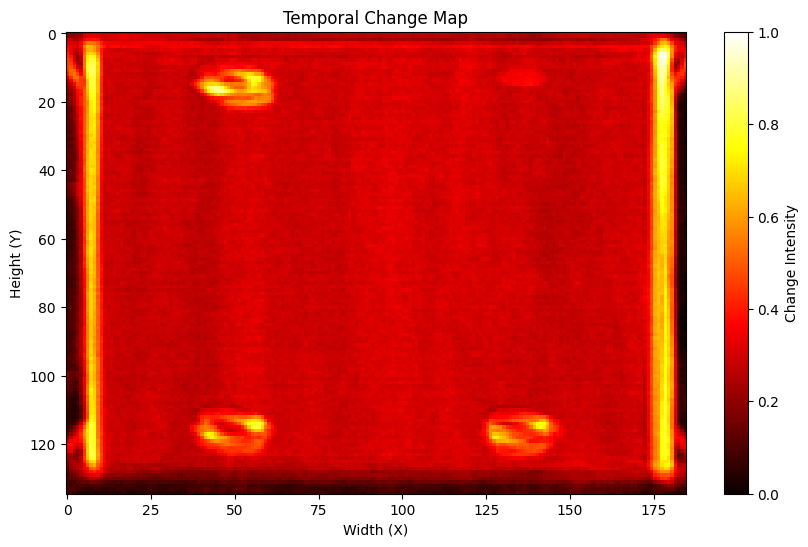

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

T, H, W = data_real.shape

data_mean = data_real

temporal_diff = np.diff(data_mean, axis=0)

change_map = np.sum(np.abs(temporal_diff), axis=0)

change_map_normalized = (change_map - change_map.min()) / np.ptp(change_map)

plt.figure(figsize=(10, 6))
plt.imshow(change_map_normalized, cmap='hot', aspect='auto')
plt.title("Temporal Change Map")
plt.colorbar(label='Change Intensity')
plt.xlabel("Width (X)")
plt.ylabel("Height (Y)")
plt.show()

In [ ]:

change_points_per_pixel = {}
threshold = 0.1

for y in range(H):
    for x in range(W):

        pixel_temporal_diff = temporal_diff[:, y, x]

        change_times = np.where(np.abs(pixel_temporal_diff) > threshold)[0]

        if len(change_times) > 0:
            change_points_per_pixel[(y, x)] = change_times

print(f"Calculated change points for {len(change_points_per_pixel)} pixels.")

Calculated change points for 24975 pixels.


1. Lightest pixel at (113, 51) with STD = 772.6200
2. Lightest pixel at (113, 135) with STD = 768.5172
3. Lightest pixel at (12, 48) with STD = 724.5935


<ipython-input-9-2654319355>:36: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(x, y, color='red', s=100, marker='x', edgecolors='black')


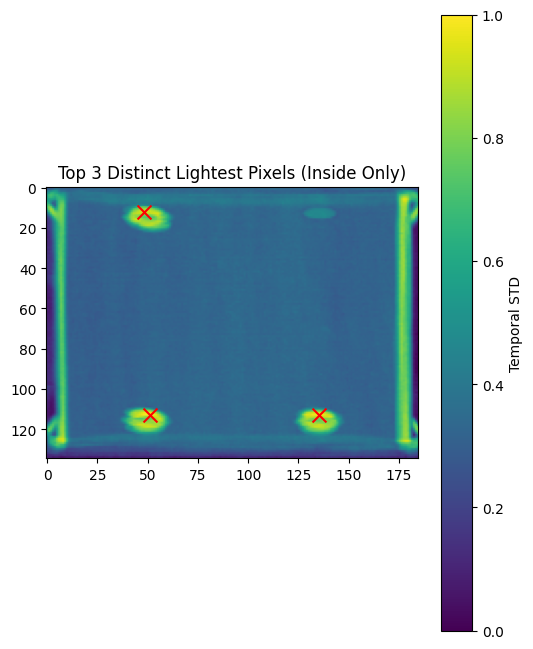

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

border = 10
num_lightest = 3
min_distance = 10

pixel_std = np.std(data_real, axis=0)

inner_std = pixel_std[border:-border, border:-border]

flat_indices = np.argsort(inner_std.ravel())[::-1]


rows_inner, cols_inner = np.unravel_index(flat_indices, inner_std.shape)

rows_full = rows_inner + border
cols_full = cols_inner + border
coords_full = list(zip(rows_full, cols_full))

selected_coords = []
for y, x in coords_full:
    if all(np.linalg.norm([y - sy, x - sx]) >= min_distance for sy, sx in selected_coords):
        selected_coords.append((y, x))
    if len(selected_coords) == num_lightest:
        break


for i, (r, c) in enumerate(selected_coords, 1):
    print(f"{i}. Lightest pixel at ({r}, {c}) with STD = {pixel_std[r, c]:.4f}")


plt.figure(figsize=(6, 8))
plt.imshow(pixel_std, cmap='viridis')
for y, x in selected_coords:
    plt.scatter(x, y, color='red', s=100, marker='x', edgecolors='black')
plt.title("Top 3 Distinct Lightest Pixels (Inside Only)")
plt.colorbar(label="Temporal STD")
plt.show()

In [ ]:
for i, (r, c) in enumerate(selected_coords, 1):
    std_value = pixel_std[r, c]
    print(f"{i}. Selected pixel at (Y={r}, X={c}) with STD = {std_value:.4f}")

1. Selected pixel at (Y=113, X=51) with STD = 772.6200
2. Selected pixel at (Y=113, X=135) with STD = 768.5172
3. Selected pixel at (Y=12, X=48) with STD = 724.5935


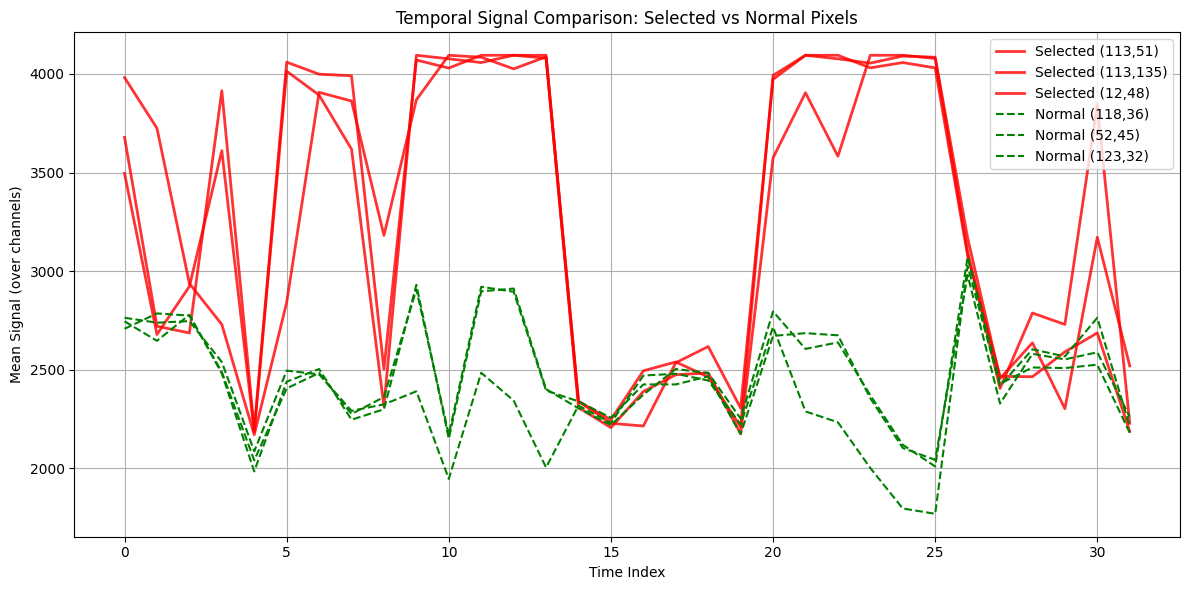

Random normal pixel coordinates:
Normal pixel at (Y=118, X=36)
Normal pixel at (Y=52, X=45)
Normal pixel at (Y=123, X=32)


In [ ]:
import random

defect_signals = []
for (y, x) in selected_coords:
    signal = data_real[:, y, x]
    defect_signals.append((f"Selected ({y},{x})", signal))

random_coords = []
while len(random_coords) < 3:
    ry = random.randint(10, H - 11)
    rx = random.randint(10, W - 11)
    if all(np.linalg.norm([ry - dy, rx - dx]) >= 15 for dy, dx in selected_coords):
        random_coords.append((ry, rx))

normal_signals = []
for (y, x) in random_coords:
    signal = data_real[:, y, x]
    normal_signals.append((f"Normal ({y},{x})", signal))


plt.figure(figsize=(12, 6))
for label, signal in defect_signals:
    plt.plot(signal, label=label, linewidth=2, color='red', alpha=0.8)

for label, signal in normal_signals:
    plt.plot(signal, label=label, linestyle='--', linewidth=1.5, color='green')

plt.title("Temporal Signal Comparison: Selected vs Normal Pixels")
plt.xlabel("Time Index")
plt.ylabel("Mean Signal (over channels)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


print("Random normal pixel coordinates:")
for (y, x) in random_coords:
    print(f"Normal pixel at (Y={y}, X={x})")

Data shape: T=32, H=135, W=185
✅ Selected normal pixels: [(np.int64(113), np.int64(136)), (np.int64(113), np.int64(49)), (np.int64(113), np.int64(50))]


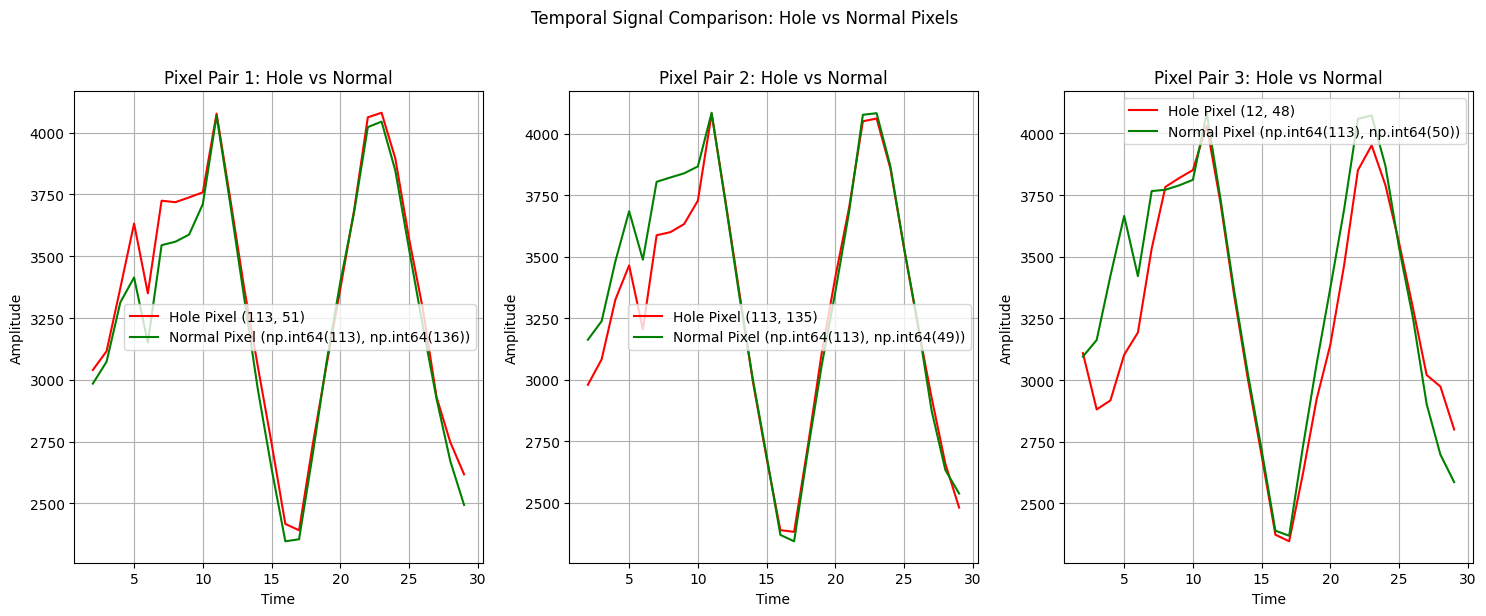

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


T, H, W = data_real.shape
print(f"Data shape: T={T}, H={H}, W={W}")


hole_pixels = [(113, 51), (113, 135), (12, 48)]

temporal_std = np.std(data_real, axis=0)

pixel_activity = temporal_std

flat_indices = np.argsort(pixel_activity.ravel())[::-1]
normal_pixels = []

border = 10
for idx in flat_indices:
    h, w = np.unravel_index(idx, (H, W))

    if (h, w) not in hole_pixels and h >= border and h < H - border and w >= border and w < W - border:
        normal_pixels.append((h, w))
    if len(normal_pixels) >= 3:
        break

print(f"✅ Selected normal pixels: {normal_pixels}")


def smooth_curve(y, window=3):

    if window % 2 == 0:
      window += 1
    if window > 1:
      return np.convolve(y, np.ones(window)/window, mode='valid')
    else:
      return y


def plot_hole_vs_normal(data_real, hole_pixels, normal_pixels, smooth_window=1):

    plt.figure(figsize=(15, 6))

    for i, (hole, normal) in enumerate(zip(hole_pixels, normal_pixels)):
        plt.subplot(1, len(hole_pixels), i + 1)

        hole_signal = data_real[:, hole[0], hole[1]]
        normal_signal = data_real[:, normal[0], normal[1]]

        if smooth_window > 1:
            hole_signal = smooth_curve(hole_signal, smooth_window)
            normal_signal = smooth_curve(normal_signal, smooth_window)

            time_axis = np.arange(len(hole_signal)) + (smooth_window - 1) // 2
        else:
             time_axis = np.arange(len(hole_signal))


        plt.plot(time_axis, hole_signal, label=f'Hole Pixel {hole}', color='red')
        plt.plot(time_axis, normal_signal, label=f'Normal Pixel {normal}', color='green')
        plt.title(f'Pixel Pair {i+1}: Hole vs Normal')
        plt.xlabel('Time')
        plt.ylabel('Amplitude')
        plt.grid(True)
        plt.legend()


    plt.suptitle('Temporal Signal Comparison: Hole vs Normal Pixels', y=1.02)
    plt.tight_layout()
    plt.show()


smooth_window = 5

plot_hole_vs_normal(data_real, hole_pixels, normal_pixels, smooth_window)

Best Hyperparameters: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}
R² Score: 0.9963
Mean Absolute Error: 5.08 kg/m³


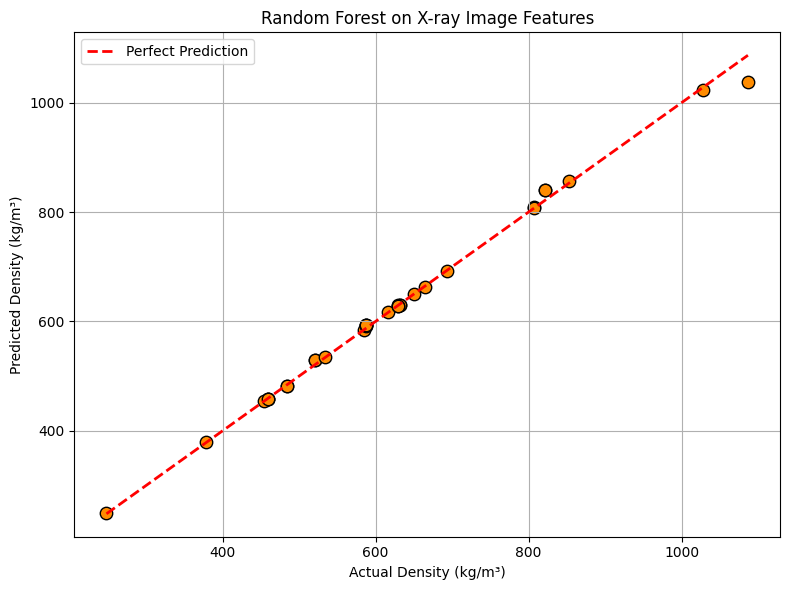

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.fft import fft2
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import r2_score, mean_absolute_error


df = pd.read_csv('/content/drive/MyDrive/wood data/wood/Dimensions/Tropical_dimensions.csv')
data_real = np.load('/content/drive/MyDrive/wood data/wood/X_ray/Copy of Tropical_XR.npy')


df["Volume_cm3"] = (df["Length (mm)"] * df["Width (mm)"] * df["Thickness (mm)"]) / 1000
MC_9 = 0.09
df["m9"] = df["Mass (g)"] / (1 + MC_9)
df["MC_t"] = MC_9 + ((df["m9"] - df["Mass (g)"]) / df["m9"]) * (1 + MC_9)

samples = []
labels = []


for i in range(data_real.shape[0]):
    image = np.abs(data_real[i])
    H, W = image.shape


    flat_image = image.reshape(-1)
    flat_std = np.abs(flat_image - flat_image.mean())
    top_idxs = np.argsort(flat_std)[-5:]

    mass = df.loc[i, "Mass (g)"]
    volume = df.loc[i, "Volume_cm3"]
    mc_t = df.loc[i, "MC_t"]
    density = df.loc[i, "Density (kg/m3)"]

    for idx in top_idxs:
        h = idx // W
        w = idx % W
        pixel_val = image[h, w]


        patch_size = 5
        h0 = max(0, h - patch_size // 2)
        h1 = min(H, h + patch_size // 2 + 1)
        w0 = max(0, w - patch_size // 2)
        w1 = min(W, w + patch_size // 2 + 1)

        patch = image[h0:h1, w0:w1]
        spectrum2d = np.abs(fft2(patch))
        fft_mean = spectrum2d.mean()
        fft_peak = spectrum2d.max()

        features = [
            mass, volume, mc_t,
            pixel_val,
            patch.std(),
            fft_mean,
            fft_peak
        ]
        samples.append(features)
        labels.append(density)


X = pd.DataFrame(samples, columns=[
    "Mass", "Volume", "MC_t",
    "Pixel_Intensity", "Patch_Std",
    "FFT2D_Mean", "FFT2D_Peak"
])
y = np.array(labels)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10],
    "min_samples_split": [2, 5]
}
grid = GridSearchCV(RandomForestRegressor(random_state=42), param_grid, cv=5, scoring='r2', n_jobs=-1)
grid.fit(X_train, y_train)

best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
print("Best Hyperparameters:", grid.best_params_)
print(f"R² Score: {r2:.4f}")
print(f"Mean Absolute Error: {mae:.2f} kg/m³")

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, color='darkorange', edgecolor='k', s=80)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2, label='Perfect Prediction')
plt.xlabel("Actual Density (kg/m³)")
plt.ylabel("Predicted Density (kg/m³)")
plt.title("Random Forest on X-ray Image Features")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


Best Hyperparameters: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}
R² Score: 0.9963
Mean Absolute Error: 5.08 kg/m³


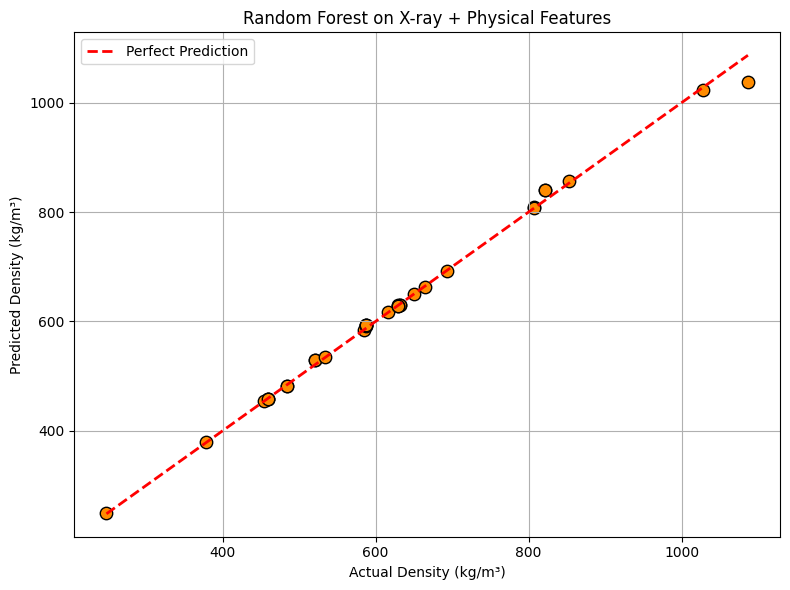

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.fft import fft2
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import r2_score, mean_absolute_error


df = pd.read_csv('/content/drive/MyDrive/wood data/wood/Dimensions/Tropical_dimensions.csv')
data_real = np.load('/content/drive/MyDrive/wood data/wood/X_ray/Copy of Tropical_XR.npy')


df["Volume_cm3"] = (df["Length (mm)"] * df["Width (mm)"] * df["Thickness (mm)"]) / 1000
MC_9 = 0.09
df["m9"] = df["Mass (g)"] / (1 + MC_9)
df["MC_t"] = MC_9 + ((df["m9"] - df["Mass (g)"]) / df["m9"]) * (1 + MC_9)

samples = []
labels = []


for i in range(data_real.shape[0]):
    image = np.abs(data_real[i])
    H, W = image.shape
    image_flat = image.reshape(-1)
    top_idxs = np.argsort(np.abs(image_flat - image_flat.mean()))[-5:]

    mass = df.loc[i, "Mass (g)"]
    volume = df.loc[i, "Volume_cm3"]
    mc_t = df.loc[i, "MC_t"]
    density = df.loc[i, "Density (kg/m3)"]

    for idx in top_idxs:
        h = idx // W
        w = idx % W
        pixel_val = image[h, w]

        patch_size = 5
        h0 = max(0, h - patch_size // 2)
        h1 = min(H, h + patch_size // 2 + 1)
        w0 = max(0, w - patch_size // 2)
        w1 = min(W, w + patch_size // 2 + 1)
        patch = image[h0:h1, w0:w1]

        spectrum2d = np.abs(fft2(patch))
        fft_mean = spectrum2d.mean()
        fft_peak = spectrum2d.max()

        features = [
            mass, volume, mc_t,
            pixel_val,
            patch.std(),
            fft_mean,
            fft_peak
        ]
        samples.append(features)
        labels.append(density)


X = pd.DataFrame(samples, columns=[
    "Mass", "Volume", "MC_t",
    "Pixel_Mean", "Pixel_Std",
    "FFT_Mean", "FFT_Peak"
])
y = np.array(labels)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10],
    "min_samples_split": [2, 5]
}
grid = GridSearchCV(RandomForestRegressor(random_state=42), param_grid, cv=5, scoring='r2', n_jobs=-1)
grid.fit(X_train, y_train)

best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print("Best Hyperparameters:", grid.best_params_)
print(f"R² Score: {r2:.4f}")
print(f"Mean Absolute Error: {mae:.2f} kg/m³")

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, color='darkorange', edgecolor='k', s=80)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2, label='Perfect Prediction')
plt.xlabel("Actual Density (kg/m³)")
plt.ylabel("Predicted Density (kg/m³)")
plt.title("Random Forest on X-ray + Physical Features")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:


y_pred_train = best_model.predict(X_train)
y_pred_test = best_model.predict(X_test)

print(f"Train R²: {r2_score(y_train, y_pred_train):.4f}")
print(f"Train MAE: {mean_absolute_error(y_train, y_pred_train):.2f} kg/m³")
print(f"Test R²: {r2_score(y_test, y_pred_test):.4f}")
print(f"Test MAE: {mean_absolute_error(y_test, y_pred_test):.2f} kg/m³")


Train R²: 0.9998
Train MAE: 1.64 kg/m³
Test R²: 0.9963
Test MAE: 5.08 kg/m³


In [ ]:
import time

start_train = time.time()
grid.fit(X_train, y_train)
train_time = time.time() - start_train
print(f"Training Time: {train_time:.2f} seconds")

start_test = time.time()
y_pred = grid.best_estimator_.predict(X_test)
test_time = time.time() - start_test
print(f"Testing Time: {test_time:.4f} seconds")


Training Time: 9.07 seconds
Testing Time: 0.0107 seconds


In [ ]:

n_pixels_per_sample = 5
n_samples = df.shape[0]
sample_indices_test = X_test.index // n_pixels_per_sample

species_test = df.loc[sample_indices_test, "Species"].values
results_df = pd.DataFrame({
    "Sample_Index": sample_indices_test,
    "Species": species_test,
    "Actual": y_test,
    "Predicted": y_pred
})

sample_results = results_df.groupby(["Sample_Index", "Species"]).agg({
    "Actual": "mean",
    "Predicted": "mean"
}).reset_index()

sample_results["Absolute Error"] = np.abs(sample_results["Actual"] - sample_results["Predicted"])

grouped_species_results = sample_results.groupby("Species").agg({
    "Actual": "mean",
    "Predicted": "mean",
    "Absolute Error": "mean"
}).sort_values("Actual")



print("\n Predicted vs Actual Density by Species (Averaged per Sample):")
print(grouped_species_results.round(2).to_string())


📋 Predicted vs Actual Density by Species (Averaged per Sample):
                   Actual  Predicted  Absolute Error
Species                                             
Samba              247.91     249.21            1.30
Ako                377.86     379.81            1.94
African mahogany   453.83     454.80            0.97
Okoume             459.34     457.96            1.39
Framire            484.06     482.22            1.84
Olon               521.03     529.95            8.92
Tiama              534.25     534.75            0.50
Niangon            584.26     584.29            0.03
Avodire            587.41     592.36            4.95
Iroko              616.72     617.58            0.85
Bete               628.80     629.37            0.56
Bosse              629.50     628.69            0.80
Sipo               631.65     629.62            2.03
Teck               649.93     650.78            0.85
Sapelli            663.96     662.29            1.67
Limba              693.28     691.

evaluation

LOSO Evaluation: 100%|██████████| 32/32 [03:57<00:00,  7.41s/it]



✅ LOSO with GridSearch:
R² Score: 0.8699
MAE: 39.06 kg/m³


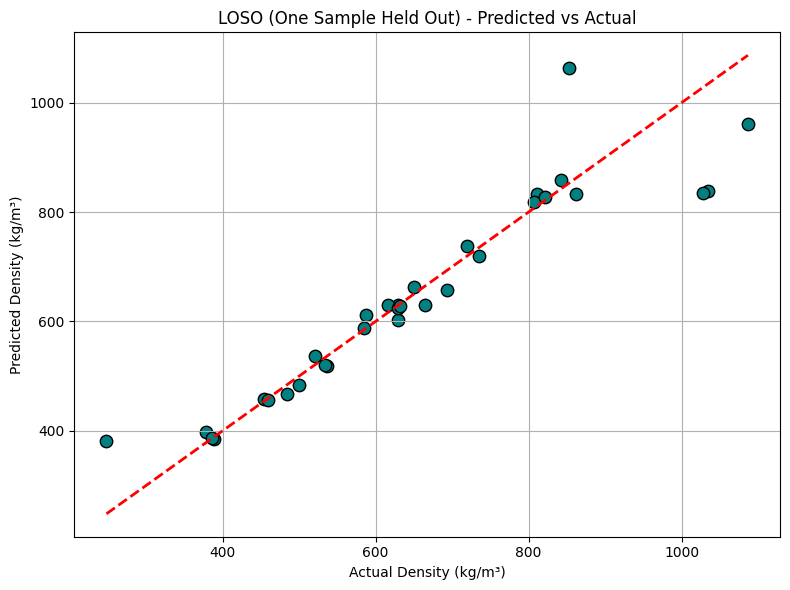

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.fft import fft2
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import r2_score, mean_absolute_error
from tqdm import tqdm

df = pd.read_csv('/content/drive/MyDrive/wood data/wood/Dimensions/Tropical_dimensions.csv')
data_real = np.load('/content/drive/MyDrive/wood data/wood/X_ray/Copy of Tropical_XR.npy')


df["Volume_cm3"] = (df["Length (mm)"] * df["Width (mm)"] * df["Thickness (mm)"]) / 1000
MC_9 = 0.09
df["m9"] = df["Mass (g)"] / (1 + MC_9)
df["MC_t"] = MC_9 + ((df["m9"] - df["Mass (g)"]) / df["m9"]) * (1 + MC_9)


samples = []
labels = []

for i in range(data_real.shape[0]):
    image = np.abs(data_real[i])
    H, W = image.shape
    image_flat = image.reshape(-1)
    top_idxs = np.argsort(np.abs(image_flat - image_flat.mean()))[-5:]

    mass = df.loc[i, "Mass (g)"]
    volume = df.loc[i, "Volume_cm3"]
    mc_t = df.loc[i, "MC_t"]
    density = df.loc[i, "Density (kg/m3)"]

    for idx in top_idxs:
        h = idx // W
        w = idx % W
        pixel_val = image[h, w]

        patch_size = 5
        h0 = max(0, h - patch_size // 2)
        h1 = min(H, h + patch_size // 2 + 1)
        w0 = max(0, w - patch_size // 2)
        w1 = min(W, w + patch_size // 2 + 1)
        patch = image[h0:h1, w0:w1]

        spectrum2d = np.abs(fft2(patch))
        fft_mean = spectrum2d.mean()
        fft_peak = spectrum2d.max()

        features = [
            mass, volume, mc_t,
            pixel_val,
            patch.std(),
            fft_mean,
            fft_peak
        ]
        samples.append(features)
        labels.append(density)


X = pd.DataFrame(samples, columns=[
    "Mass", "Volume", "MC_t",
    "Pixel_Mean", "Pixel_Std",
    "FFT_Mean", "FFT_Peak"
])
y = np.array(labels)


num_samples = df.shape[0]
preds = []
true_vals = []

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10],
    "min_samples_split": [2, 5]
}

for i in tqdm(range(num_samples), desc="LOSO Evaluation"):
    test_idx = list(range(i * 5, (i + 1) * 5))
    train_idx = list(set(range(len(X))) - set(test_idx))

    X_train = X.iloc[train_idx]
    y_train = y[train_idx]
    X_test = X.iloc[test_idx]
    y_test = y[test_idx]

    grid = GridSearchCV(
        RandomForestRegressor(random_state=42),
        param_grid,
        cv=3,
        scoring='r2',
        n_jobs=-1
    )
    grid.fit(X_train, y_train)
    best_model = grid.best_estimator_

    y_pred = best_model.predict(X_test)
    preds.append(np.mean(y_pred))
    true_vals.append(y_test[0])


r2 = r2_score(true_vals, preds)
mae = mean_absolute_error(true_vals, preds)

print("\n LOSO with GridSearch:")
print("R² Score:", round(r2, 4))
print("MAE:", round(mae, 2), "kg/m³")


plt.figure(figsize=(8, 6))
plt.scatter(true_vals, preds, color='teal', edgecolor='k', s=80)
plt.plot([min(true_vals), max(true_vals)], [min(true_vals), max(true_vals)], 'r--', lw=2)
plt.xlabel("Actual Density (kg/m³)")
plt.ylabel("Predicted Density (kg/m³)")
plt.title("LOSO (One Sample Held Out) - Predicted vs Actual")
plt.grid(True)
plt.tight_layout()
plt.show()
